In [183]:
import pandas as pd
import numpy as np

import statsmodels.formula.api as smf

In [184]:
df = pd.read_stata('Integration.dta')
df.columns

Index(['id', 'mand', 'ankomstaar', 'alder', 'aarslon', 'aar'], dtype='object')

#### Problem 1 a.

In [185]:
df['kohorte14'] = (df.ankomstaar == 2014.0).astype(int)
df['kohorte15'] = (df.ankomstaar == 2015.0).astype(int)
df['kohorte16'] = (df.ankomstaar == 2016.0).astype(int)

data2017 = df[df['aar'] == 2017]
data2018 = df[df['aar'] == 2018]

In [186]:
print(f'Gennemsnit for 2017: \n {data2017.groupby('mand').mean()}')
print(f'Gennemsnit for 2018: \n {data2018.groupby('mand').mean()}')

Gennemsnit for 2017: 
                id   ankomstaar      alder       aarslon     aar  kohorte14  \
mand                                                                         
0.0   1220.713135  2014.981812  28.628283  31124.437500  2017.0   0.341414   
1.0   1195.247803  2015.017822  28.670341  61324.046875  2017.0   0.332808   

      kohorte15  kohorte16  
mand                        
0.0    0.335354   0.323232  
1.0    0.316535   0.350656  
Gennemsnit for 2018: 
                id   ankomstaar      alder       aarslon     aar  kohorte14  \
mand                                                                         
0.0   1220.713135  2014.981812  29.628283  40045.046875  2018.0   0.341414   
1.0   1195.247803  2015.017822  29.670341  90906.500000  2018.0   0.332808   

      kohorte15  kohorte16  
mand                        
0.0    0.335354   0.323232  
1.0    0.316535   0.350656  


#### Problem 1 b.

In [187]:
data2017['YSM'] = data2017.aar - data2017.ankomstaar
data2017['laarslon'] = np.log(data2017.aarslon)

model = smf.ols('laarslon ~ alder + YSM', data = data2017)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               laarslon   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     39.84
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           9.53e-18
Time:                        20:31:16   Log-Likelihood:                -1639.8
No. Observations:                2400   AIC:                             3286.
Df Residuals:                    2397   BIC:                             3303.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.4231      0.047    219.799      0.0

C:\Users\kleme\AppData\Local\Temp\ipykernel_20148\4060634579.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2017['YSM'] = data2017.aar - data2017.ankomstaar
C:\Users\kleme\AppData\Local\Temp\ipykernel_20148\4060634579.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2017['laarslon'] = np.log(data2017.aarslon)


#### Problem 1 c.

For, at få den nye estimator som er samlet af $\theta = \tilde{\beta_1}+\tilde{\beta_2}$, samler vi den så vi får parameteren $\tilde{\beta_1} = \theta - \tilde{\beta_2}$

Vi kan sætte det ind i vores model 1. $\ln{(aarslon)} = \tilde{\beta_0} + (\theta - \tilde{\beta_2})alder_i+\tilde{\beta_2}YSM + u_i$

Det giver os modellen:

$\ln{(aarslon)} = \tilde{\beta_0} + \theta alder_i + \tilde{\beta_2}(YSM - alder_i) + u_i$


In [188]:
data2017['YSMMinusAlder'] = data2017['YSM'] - data2017['alder']
model1c = smf.ols('laarslon ~ alder + YSMMinusAlder', data = data2017)
result1c = model1c.fit()
print(result1c.summary())

                            OLS Regression Results                            
Dep. Variable:               laarslon   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     39.84
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           9.53e-18
Time:                        20:31:16   Log-Likelihood:                -1639.8
No. Observations:                2400   AIC:                             3286.
Df Residuals:                    2397   BIC:                             3303.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        10.4231      0.047    219.799

C:\Users\kleme\AppData\Local\Temp\ipykernel_20148\3282313307.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2017['YSMMinusAlder'] = data2017['YSM'] - data2017['alder']


#### Problem 2 a.

In [189]:
df['laarslon'] = np.log(df.aarslon)
df['YSM'] = df.aar - df.ankomstaar
model2 = smf.ols('laarslon ~ alder + YSM + ankomstaar', data=df)
results2 = model2.fit()
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:               laarslon   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     125.4
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           3.61e-78
Time:                        20:31:16   Log-Likelihood:                -4102.0
No. Observations:                4800   AIC:                             8212.
Df Residuals:                    4796   BIC:                             8238.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -457.8689     38.818    -11.795      0.0

#### Problem 3 a.

$\ln(aarslon)_{it} = \gamma_0 + \gamma_1 alder + \gamma_2 alder^2 + \gamma_3 YSM + \gamma_4 YSM^2 + \gamma_5 2015.0 + \gamma_6 2016.0$ 

In [190]:
df['YSMMinusAlder'] = df['YSM'] - df['alder']
df['alder2'] = df.alder**2
df['YSM2'] = df.YSM**2
model3 = smf.ols('laarslon ~ alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16', data=df)
results3 = model3.fit()
print(results3.summary())


                            OLS Regression Results                            
Dep. Variable:               laarslon   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     114.6
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          1.48e-135
Time:                        20:31:17   Log-Likelihood:                -3961.5
No. Observations:                4800   AIC:                             7937.
Df Residuals:                    4793   BIC:                             7982.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.0633      0.128     62.821      0.0

#### Problem 3 b

In [191]:
from scipy import stats
print(results3.f_test('alder2 = 0, YSM2 = 0, kohorte15*2 = kohorte16'))

<F test: F=96.3057538416977, p=1.5913420915091572e-60, df_denom=4.79e+03, df_num=3>


Vi laver nu modellen hvor vi har mand som dummy variable og med interaktions led med alle vores parametere, vi tester så om det er 0.

In [192]:
result3medKøn = smf.ols('laarslon ~ mand*(alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16)', data=df).fit()

mandVariable = ["mand", "mand:alder", "mand:alder2", "mand:YSM", "mand:YSM2",
         "mand:kohorte15", "mand:kohorte16"]

print(result3medKøn.f_test(", ".join(f"{n} = 0" for n in mandVariable)))

<F test: F=321.45853691269116, p=0.0, df_denom=4.79e+03, df_num=7>


#### Problem 3 c

In [203]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

BP    LM, p: 519.2356900065063 6.0309705609933255e-109  F, p: 100.00986311386973 3.472188034747999e-117
White LM, p: 535.5655081312239 5.982635213259725e-103


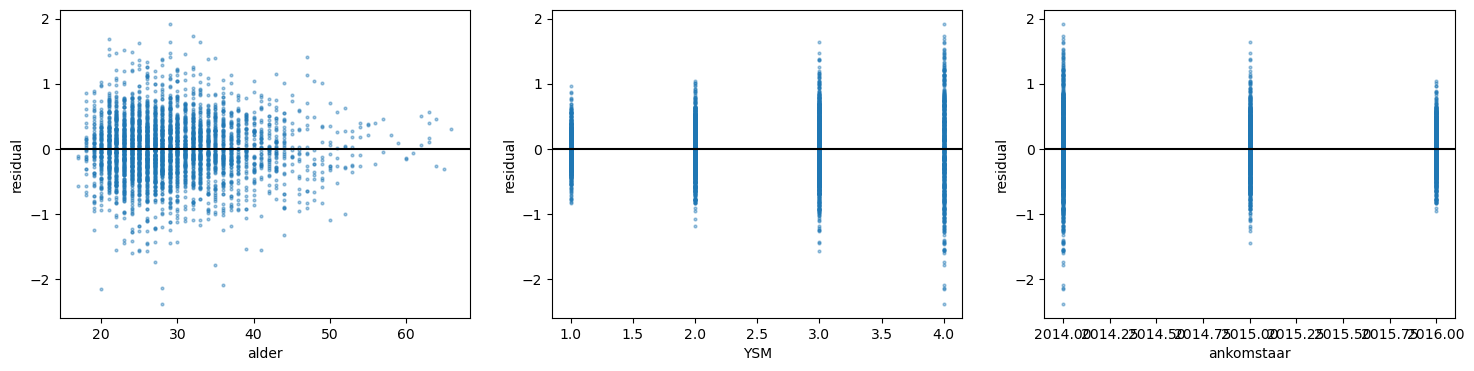

In [210]:
kunMænd = df[df['mand'] == 1]
kunMændModel = smf.ols('laarslon ~ alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16', data=kunMænd)
kunMændResultat = kunMændModel.fit()

m = kunMændResultat
df_r = df.loc[m.model.data.row_labels].copy()
df_r["resid"], df_r["fitted"] = m.resid, m.fittedvalues

import matplotlib.pyplot as plt

# Breusch-Pagan og White
bp = het_breuschpagan(m.resid, m.model.exog)
wh = het_white(m.resid, m.model.exog)
print("BP    LM, p:", bp[0], bp[1], " F, p:", bp[2], bp[3])
print("White LM, p:", wh[0], wh[1])

# Grafer
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, v in zip(ax, ["alder", "YSM", "ankomstaar"]):
    a.scatter(df_r[v], df_r["resid"], s=4, alpha=.4)
    a.axhline(0, color="k"); a.set_xlabel(v); a.set_ylabel("residual")
plt.show()


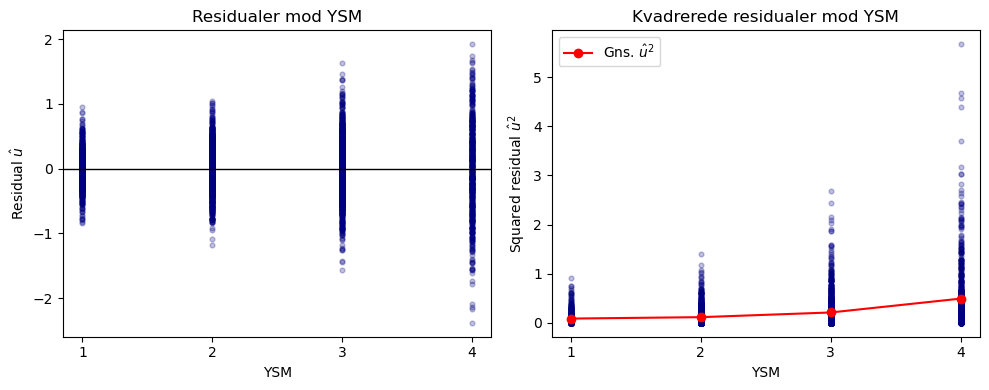

In [218]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Venstre: residualer mod YSM
axes[0].scatter(kunMænd['YSM'], m.resid, s=12, alpha=0.25, color='navy')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_xlabel('YSM'); axes[0].set_ylabel(r'Residual $\hat u$')
axes[0].set_title('Residualer mod YSM')

# Højre: kvadrerede residualer mod YSM med gennemsnit pr. YSM
axes[1].scatter(kunMænd['YSM'], m.resid**2, s=12, alpha=0.25, color='navy')
gns = kunMænd.groupby('YSM')['u2'].mean()
axes[1].plot(gns.index, gns.values, color='red', marker='o', label=r'Gns. $\hat u^2$')
axes[1].set_xlabel('YSM'); axes[1].set_ylabel(r'Squared residual $\hat u^2$')
axes[1].set_title('Kvadrerede residualer mod YSM')
axes[1].legend()

for ax in axes:
    ax.set_xticks([1, 2, 3, 4])   # YSM tager kun værdierne 1-4

fig.tight_layout()
plt.show()

In [ ]:
np.random.seed(2308)

beta_true = np.array([2.0, 3.0, -1.0, -1.0]) 
a = 3.0                                          
alpha = 0.05

def simulate(n):
    x1, x2, x3 = (np.random.normal(1, 2, n) for _ in range(3))
    eps = np.random.normal(0, 0.5 * x1**2, n)
    y = beta_true[0] + beta_true[1]*x1 + beta_true[2]*x2 + beta_true[3]*x3 + eps
    return pd.DataFrame({'y': y, 'x1': x1, 'x2': x2, 'x3': x3})

def monte_carlo(n, S=1000):
    out = []
    for s in range(S):
        d = simulate(n)
        ols = smf.ols('y ~ x1 + x2 + x3', data=d).fit()
        wls = smf.wls('y ~ x1 + x2 + x3', data=d, weights=4 / d['x1']**4).fit()  # w = 1/Var(eps|x)
        out.append([ols.params['x1'], ols.bse['x1'], ols.HC1_se['x1'],
                    wls.params['x1'], wls.bse['x1']])
    return pd.DataFrame(out, columns=['b_ols', 'se_ols', 'se_rob', 'b_wls', 'se_wls'])

def summary_table(res, n, k=4):
    crit = stats.t.ppf(1 - alpha/2, n - k)            
    rej = lambda b, se: np.mean(np.abs((b - a) / se) > crit)
    return pd.DataFrame({
        'Mean b1':   [res.b_ols.mean(),   res.b_ols.mean(),   res.b_wls.mean()],
        'SD b1':     [res.b_ols.std(),    res.b_ols.std(),    res.b_wls.std()],
        'Mean SE':   [res.se_ols.mean(),  res.se_rob.mean(),  res.se_wls.mean()],
        'Reject H0': [rej(res.b_ols, res.se_ols), rej(res.b_ols, res.se_rob), rej(res.b_wls, res.se_wls)]},
        index=['OLS, usual SE', 'OLS, robust SE (HC1)', 'WLS'])

for n in [1000, 50]:
    res = monte_carlo(n, S=1000)
    print(f'n = {n}'); display(summary_table(res, n).round(4))

n = 1000


,Mean b1,SD b1,Mean SE,Reject H0
"OLS, usual SE",3.0045,0.1359,0.0671,0.313
"OLS, robust SE (HC1)",3.0045,0.1359,0.1364,0.058
WLS,3.0000,0.0025,0.0023,0.045


n = 50


,Mean b1,SD b1,Mean SE,Reject H0
"OLS, usual SE",2.9870,0.6066,0.2872,0.316
"OLS, robust SE (HC1)",2.9870,0.6066,0.4995,0.092
WLS,2.9968,0.0520,0.0479,0.045
